# Check convergence 

In [1]:
import cobra
import pandas as pd
import numpy as np
from os import listdir
import warnings
import seaborn as sns
from collections import OrderedDict
import json
import os
import matplotlib.pyplot as plt
import math



from reframed.community.model import Community
from reframed import Environment, set_default_solver
from steadiercom.cli import load_communities,load_media_db

import seaborn as sns

import sys

sys.path.append("../functions/")
from convergence import SteadierSampleConvergence

In [2]:
import scipy

In [3]:
%load_ext autoreload
%autoreload 2

In [4]:
std = lambda x:np.std(x,ddof=1)
cv = lambda x: std(x)/ abs(np.mean(x)) * 100 
def std_sample_size(dfs_tot_abs,sample_sizes,cutoff=1e-6 ):
    datas_std = {}
    datas_cv = {}
    for n in sample_sizes:
        sample_size = int(n)

        number = math.floor(dfs_tot_abs.shape[1]/sample_size)
        data = pd.DataFrame.from_dict({f"set{i}":dfs_tot_abs[np.arange(0+i*sample_size,(i+1)*sample_size)].T.mean() for i in np.arange(0,number)})
    
        # Cutoff data that is actually zero
        equal_zero= data.sum(axis=1).apply(abs).sort_values() <cutoff 
        data = data.loc[~equal_zero]

        data_std = data.T.apply(std)
        datas_std[sample_size]=data_std 
        data_cv = data.T.apply(cv)
        datas_cv[sample_size]=data_cv 
    return datas_std,datas_cv

def std_sampling_grouped(dfs_tot_abs,sample_sizes):
    statistics = {}
    statistics_cv = {}
    for n in sample_sizes:
        b = -6

        statistics[n]={}
        statistics_cv[n]={}
        for a in np.linspace(-5.5,1,14):

            sample_size = int(n)
            
            # Number of sets it's possible to make with same number of samples
            number = math.floor(dfs_tot_abs.shape[1]/sample_size)

            # For sample sizes of x calculate the mean value in each group of samples
            data = pd.DataFrame.from_dict({f"set{i}":dfs_tot_abs[np.arange(0+i*sample_size,(i+1)*sample_size)].T.mean() for i in np.arange(0,number)})
            
            # Remove variables with average frequency below or above thresholds
            data_set_lower= data.mean(axis=1).apply(abs).sort_values() <10**(a)
            data_set_upper = data.mean(axis=1).apply(abs).sort_values() >10**(b)
            data_bound = data_set_lower * data_set_upper
            data = data.loc[data_bound]
            
            data_std = data.T.apply(std)
            mean_std = data_std.mean()

            data_cv = data.T.apply(cv)
            mean_cv = data_cv.mean()

            statistics[n][(round(10**b,6),round(10**a,6))] =mean_std
            statistics_cv[n][(round(10**b,6),round(10**a,6))] =mean_cv
            b=a
    return statistics,statistics_cv


def std_sampling_grouped_freq(dfs_tot_abs,sample_sizes):
    statistics = {}
    statistics_cv = {}
    for n in sample_sizes:
        b = 0

        statistics[n]={}
        statistics_cv[n]={}
        for a in np.linspace(0.1,1,10):

            sample_size = int(n)
            number = math.floor(dfs_tot_abs.shape[1]/sample_size)

            # For sample sizes of x calculate the mean value in each group of samples
            data = pd.DataFrame.from_dict({f"set{i}":dfs_tot_abs[np.arange(0+i*sample_size,(i+1)*sample_size)].T.mean() for i in np.arange(0,number)})
            
            # For sample sizes of x calculate the frequency of the observation of values above 1e-6
            data_freq = pd.DataFrame.from_dict({f"set{i}":(dfs_tot_abs[np.arange(0+i*sample_size,(i+1)*sample_size)].T>1e-6).sum()/sample_size for i in np.arange(0,number)})
            
            # Remove variables with average frequency below or above thresholds
            data_set_lower= data_freq.mean(axis=1).sort_values() <a
            data_set_upper = data_freq.mean(axis=1).sort_values() >b
            data_bound = data_set_lower * data_set_upper
            data = data.loc[data_bound]

            # Calculate std and cv
            data_std = data.T.apply(std)
            mean_std = data_std.mean()

            data_cv = data.T.apply(cv)
            mean_cv = data_cv.mean()
            
            statistics[n][(round(b,2),round(a,2))] =mean_std
            statistics_cv[n][(round(b,2),round(a,2))] =mean_cv
            b=a
    return statistics,statistics_cv

### Gut microbiome community

Concentration $X_0$ (right after serial transfer) and $X_1$ (right before next transfer) in $t_0$ and $t_1$

$$
X_1 = X_0 *e^{\mu t_1} , X_0 = X_0
$$

Assuming that the cells grow back to the original concentration (after being diluted 1:20 => the cells increase in density by 20 times)

$$
X_1/X_0 = 21 = e^{\mu t} 
$$

The above equation turns into:
$$
ln(X_1/X_0) = \mu t
$$

Which means the avearage growth rate becomes
$$
\mu_{avg} = \frac{ln(20)}{t}
$$

**Methods (From Venturelli et al. 2018): 1:20 dilution every 24 h**

In [5]:
np.log(20)/24

np.float64(0.12482217806474961)

In [6]:
mediadb = "../data/Venturelli2018/generated/media_db.tsv"#path to mediadb
medium = "LB_extend"
growth = np.log(20)/24# average growth rate

models = ["../models/Venturelli2018/species_used_noO2/"+name for name in listdir("../models/Venturelli2018/species_used_noO2/")]
communities = "../data/Venturelli2018/generated/communities_steadiercom_no_abundance/NONE_abundance.tsv"

comm_id = "NONE"

output_dir = "../output/Venturelli2018/convergence_test_no_abundance//"

In [7]:
%%time

abstol = 1e-6
model_cache, comm_dict, has_abundance = load_communities(models, communities, exchange_detection='R_EX_(?!biomass__40__e__41__)')

media_db, media_has_bounds = load_media_db(mediadb)
results = []

organisms = comm_dict[comm_id]

comm_models = [model_cache.get_model(org_id, reset_id=True) for org_id in organisms]
community = Community(comm_id, comm_models, copy_models=False)

env = Environment.from_reactions(media_db[medium],max_uptake=10)
env.apply(community.merged_model, inplace=False, exclusive=True, warning=False)
env_dict = dict(env)

print(f'simulating {comm_id} in {medium} medium')

sol_df = SteadierSampleConvergence(community,output_dir=output_dir,n=20001, growth=growth, allocation=True, constraints=env)

simulating NONE in LB_extend medium
Set parameter Username
Academic license - for non-commercial use only - expires 2026-03-27


/Users/idunmariaburgos/SteadierCom/reframed/reframed/solvers/gurobi_solver.py:133: UserWarning: Constrained variable 'R_EX_pydxn_R__91__e__93__' not previously declared
  warn(f"Constrained variable '{r_id}' not previously declared")
/Users/idunmariaburgos/SteadierCom/reframed/reframed/solvers/gurobi_solver.py:133: UserWarning: Constrained variable 'R_EX_thym__91__e__93__' not previously declared
  warn(f"Constrained variable '{r_id}' not previously declared")


Round 200. Time passed: 1.91 minutes


/Users/idunmariaburgos/SteadierCom/reframed/reframed/solvers/gurobi_solver.py:133: UserWarning: Constrained variable 'R_EX_pydxn_R__91__e__93__' not previously declared
  warn(f"Constrained variable '{r_id}' not previously declared")
/Users/idunmariaburgos/SteadierCom/reframed/reframed/solvers/gurobi_solver.py:133: UserWarning: Constrained variable 'R_EX_thym__91__e__93__' not previously declared
  warn(f"Constrained variable '{r_id}' not previously declared")


Round 400. Time passed: 1.91 minutes


...

Round 19600. Time passed: 2.01 minutes


/Users/idunmariaburgos/SteadierCom/reframed/reframed/solvers/gurobi_solver.py:133: UserWarning: Constrained variable 'R_EX_pydxn_R__91__e__93__' not previously declared
  warn(f"Constrained variable '{r_id}' not previously declared")
/Users/idunmariaburgos/SteadierCom/reframed/reframed/solvers/gurobi_solver.py:133: UserWarning: Constrained variable 'R_EX_thym__91__e__93__' not previously declared
  warn(f"Constrained variable '{r_id}' not previously declared")


Round 19800. Time passed: 2.43 minutes


/Users/idunmariaburgos/SteadierCom/reframed/reframed/solvers/gurobi_solver.py:133: UserWarning: Constrained variable 'R_EX_pydxn_R__91__e__93__' not previously declared
  warn(f"Constrained variable '{r_id}' not previously declared")
/Users/idunmariaburgos/SteadierCom/reframed/reframed/solvers/gurobi_solver.py:133: UserWarning: Constrained variable 'R_EX_thym__91__e__93__' not previously declared
  warn(f"Constrained variable '{r_id}' not previously declared")


Round 20000. Time passed: 1.96 minutes
CPU times: user 3h 21min 51s, sys: 1min 19s, total: 3h 23min 11s
Wall time: 3h 24min 53s


In [8]:
dfs = []
for d in os.listdir("../output/Venturelli2018/convergence_test_no_abundance/"):
    if d.endswith(".tsv"):
        df = pd.read_csv("../output/Venturelli2018/convergence_test_no_abundance/"+str(d),sep="\t",index_col=(0,1))
        dfs.append(df)

dfs_tot = pd.concat(dfs,axis=1)
dfs_tot = dfs_tot.T.drop_duplicates().T
dfs_tot.columns = np.arange(0,dfs_tot.shape[1])

# Separate positive and degative values
pos = dfs_tot[dfs_tot>0].dropna(how="all").copy()
neg = dfs_tot[dfs_tot<0].dropna(how="all").map(abs).copy()

neg["type"]="neg"
pos["type"]="pos"
neg.set_index("type",append=True,inplace=True)
pos.set_index("type",append=True,inplace=True)

dfs_tot_abs_nan = pd.concat([pos,neg],axis=0)
dfs_tot_abs = dfs_tot_abs_nan.fillna(0)

In [9]:
dfs_tot_abs.mean().mean()

np.float64(0.012517402782250713)

### Plotting standard deviation based on sample size

The x-axis shows the number of samples in each set. The y-axis shows the standard deviation across all sets of the same size. We expect a higher number of samples in each set to cover more alternative optima and thereby reduce the variance between sets.

We see that there is lower variance between sets when their sample size is large.

In [10]:
base = 10
sample_sizes = [int(base * 2**i) for i in range(12)] 
sample_sizes = [s for s in sample_sizes if s<10000]

sample_sizes_higher_res = np.arange(1000,11000,1000)
sample_sizes_lower_res = np.arange(100,1000,100)


datas,datas_cv = std_sample_size(dfs_tot_abs,sample_sizes)
datas_higher_res,datas_higher_res_cv = std_sample_size(dfs_tot_abs,sample_sizes_higher_res)
datas_lower_res,datas_lower_res_cv = std_sample_size(dfs_tot_abs,sample_sizes_lower_res)

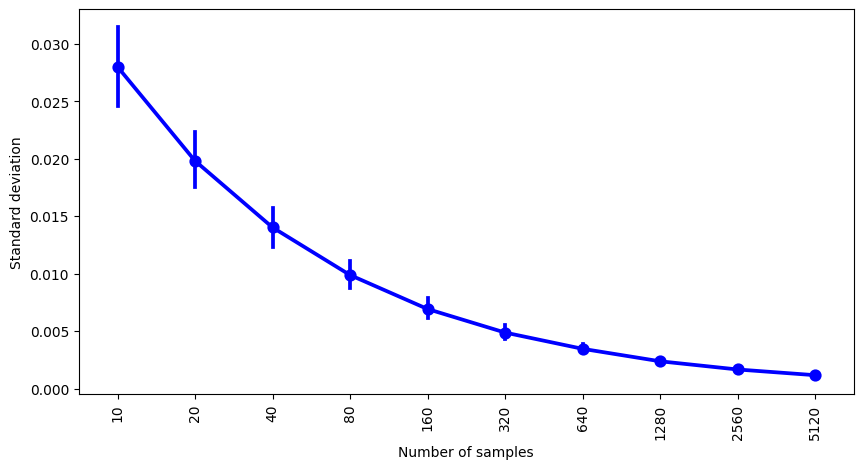

In [11]:
fig = plt.figure(figsize =(10, 5))
ax = fig.add_subplot(111)
ax = sns.pointplot(pd.DataFrame(datas),ax=ax, color="blue")
ticks = plt.xticks(rotation=90)

ax.set_ylabel("Standard deviation")
ax.set_xlabel("Number of samples")
plt.savefig("figures_meeting/convergence_gut_noabund.png",bbox_inches="tight")

(0.0, 0.05)

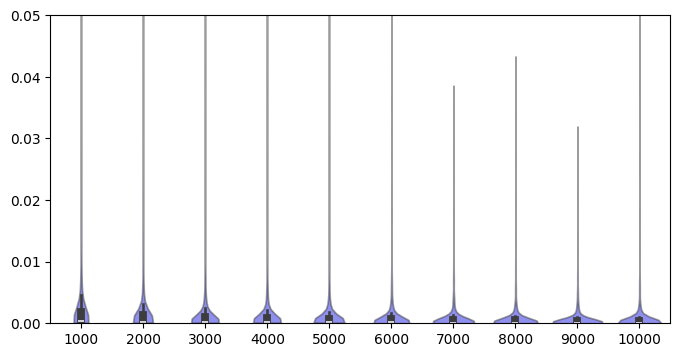

In [22]:
fig = plt.figure(figsize =(8, 4))
ax = fig.add_subplot(111)
ax = sns.violinplot(pd.DataFrame(datas_higher_res),cut=0,ax=ax,color="blue",alpha=0.5)
ax.set_ylim([0,5e-2])

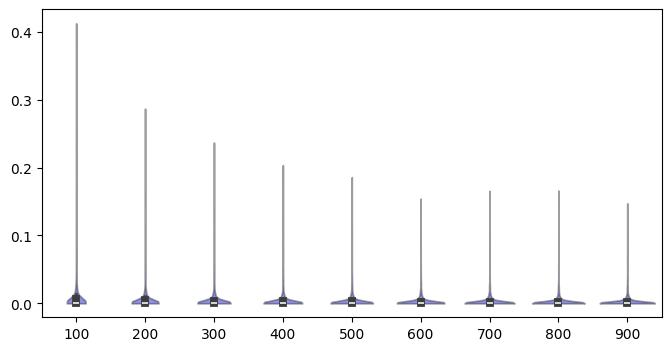

In [13]:
fig = plt.figure(figsize =(8, 4))
ax = fig.add_subplot(111)
ax = sns.violinplot(pd.DataFrame(datas_lower_res),cut=0,ax=ax,color="blue",alpha=0.5)
#ax.set_ylim([0,1e-2])

### Plotting standard deviation based on average flux rate and sample size

The x-axis represent the range of average flux rate across different sets (example: flux is between 1e-6 and 3e-6). The y-axis represents the coefficient of variance. 

We see that when the average flux is higher the coefficient of variance is lower.

In [14]:
statistics,statistics_cv = std_sampling_grouped(dfs_tot_abs,sample_sizes)

statistics_higher_res,statistics_higher_res_cv = std_sampling_grouped(dfs_tot_abs,sample_sizes_higher_res)
       

(0.0, 0.2)

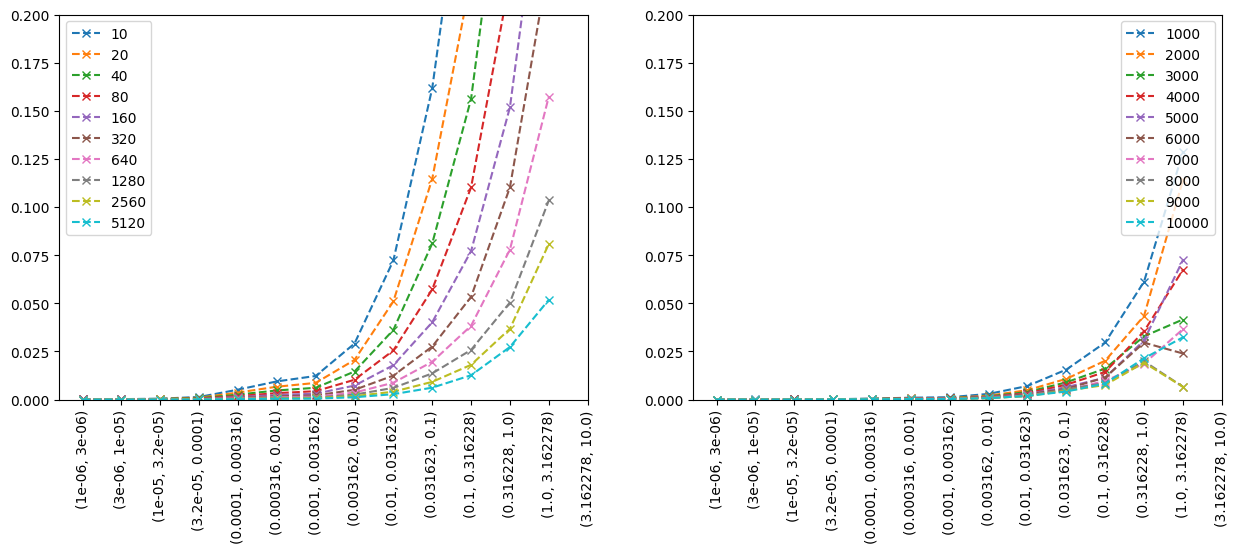

In [15]:
fig,(ax1,ax2) = plt.subplots(1,2,figsize=(15,5))

ax1 = pd.DataFrame(statistics).plot(ax=ax1,marker="x",linestyle="--")
ax1.set_xticks(np.arange(0,len(pd.DataFrame(statistics).index.values)))
ax1.set_xticklabels(pd.DataFrame(statistics).index.values,rotation=90)
ax1.legend(loc="upper left")
ax1.set_ylim([0,0.2])

ax2 = pd.DataFrame(statistics_higher_res).plot(ax=ax2,marker="x",linestyle="--")
ax2.set_xticks(np.arange(0,len(pd.DataFrame(statistics_higher_res).index.values)))
ax2.set_xticklabels(pd.DataFrame(statistics_higher_res).index.values,rotation=90)
ax2.legend(loc="upper right")
ax2.set_ylim([0,0.2])

(0.0, 100.0)

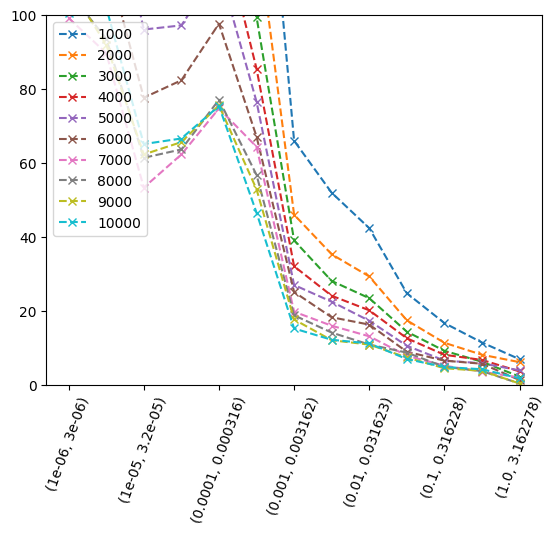

In [16]:
ax = pd.DataFrame(statistics_higher_res_cv).plot(marker="x",linestyle="--")
xticks = plt.xticks(rotation=70)
plt.legend(loc="upper left")
ax.set_ylim([0,100])

In [17]:
stats_high_res = pd.DataFrame(statistics_higher_res_cv)
diff = (stats_high_res.T.iloc[1:].reset_index(drop=True)-stats_high_res.T.iloc[:-1].reset_index(drop=True))

index = pd.Index(list(zip(np.arange(1000,10000,1000),np.arange(2000,11000,1000))))
diff.set_index(keys=index,inplace=True)

In [18]:
diff.T.mean()

1000  2000    -39.612784
2000  3000    -21.306767
3000  4000     -6.929224
4000  5000     -7.330380
5000  6000     -8.185202
6000  7000    -11.483825
7000  8000      0.707417
8000  9000     -0.553946
9000  10000    -0.042213
dtype: float64

**Sort based on frequency**

In [19]:
statistics_freq,statistics_freq_cv = std_sampling_grouped_freq(dfs_tot_abs,sample_sizes)
statistics_freq_higher_res, statistics_freq_higher_res_cv = std_sampling_grouped_freq(dfs_tot_abs,sample_sizes_higher_res)

(0.0, 0.05)

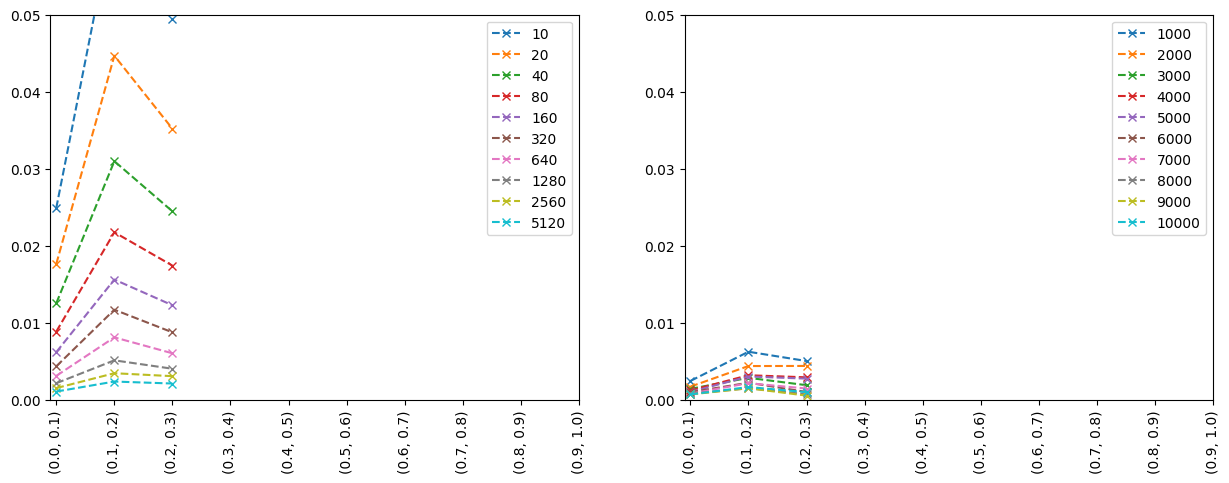

In [20]:
fig,(ax1,ax2) = plt.subplots(1,2,figsize=(15,5))
stats_df_freq = pd.DataFrame(statistics_freq)
ax1 = stats_df_freq.plot(ax=ax1,marker="x",linestyle="--")
labels =ax1.set_xticks(np.arange(len(stats_df_freq.index)))
labels = ax1.set_xticklabels(stats_df_freq.index,rotation=90)
ax1.set_ylim([0,0.05])

stats_df_freq = pd.DataFrame(statistics_freq_higher_res)
ax2 = stats_df_freq.plot(ax=ax2,marker="x",linestyle="--")
labels =ax2.set_xticks(np.arange(len(stats_df_freq.index)))
labels = ax2.set_xticklabels(stats_df_freq.index,rotation=90)
ax2.set_ylim([0,0.05])


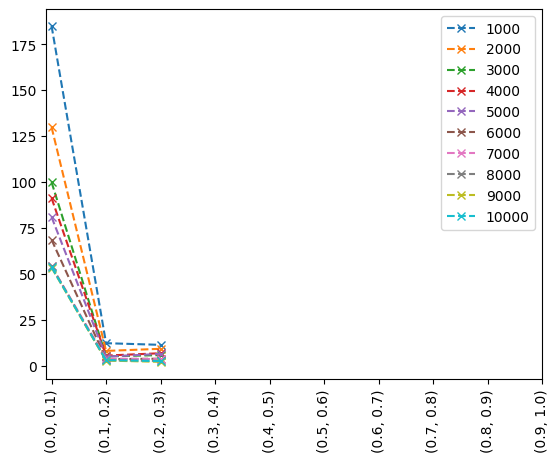

In [21]:
stats_df_freq = pd.DataFrame(statistics_freq_higher_res_cv)
ax = stats_df_freq.plot(marker="x",linestyle="--")
labels =ax.set_xticks(np.arange(len(stats_df_freq.index)))
labels = ax.set_xticklabels(stats_df_freq.index,rotation=90)

**Overview over results with filtering**

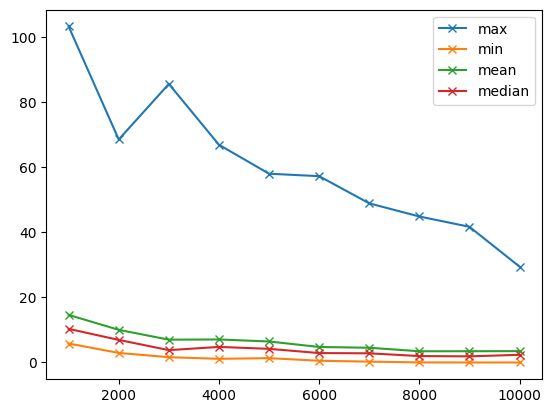

In [23]:
# For sample sizes of x calculate the frequency of the observation of values above 1e-6
sample_size=20000
data_freq = (dfs_tot_abs.T>1e-6).sum()/sample_size
index1 = data_freq>0.1

index2 = dfs_tot_abs.T.mean()>0.001
index = index1*index2
ax = pd.DataFrame(datas_higher_res_cv).loc[index].max().plot(marker='x',label="max")
ax = pd.DataFrame(datas_higher_res_cv).loc[index].min().plot(ax=ax,marker='x',label="min")
ax = pd.DataFrame(datas_higher_res_cv).loc[index].mean().plot(ax=ax,marker='x',label="mean")
ax = pd.DataFrame(datas_higher_res_cv).loc[index].median().plot(ax=ax,marker='x',label="median")
ax.legend()


In [24]:
pd.DataFrame(datas_higher_res_cv).loc[index].mean()

1000     14.615571
2000     10.024502
3000      7.007524
4000      7.071447
5000      6.450998
6000      4.764138
7000      4.526739
8000      3.449213
9000      3.462113
10000     3.495821
dtype: float64

In [25]:
data_high_df = pd.DataFrame(datas_higher_res_cv).loc[index][3000]

max_v = data_high_df.max()
data_high_df[data_high_df>0.5*max_v]

                                                         type
Faecalibacterium_prausnitzii_A2_165  M_ade__91__e__93__  neg     85.517337
Name: 3000, dtype: float64

In [26]:
index_high = data_high_df[data_high_df>0.5*max_v].index
dfs_tot_abs.loc[index_high].T.mean()

                                                         type
Faecalibacterium_prausnitzii_A2_165  M_ade__91__e__93__  neg     0.003979
dtype: float64

## E.coli mutants community

Concentration $X_0$ (right after serial transfer) and $X_1$ (right before next transfer) in $t_0$ and $t_1$

$$
X_1 = X_0 *e^{\mu t_1} , X_0 = X_0
$$

Assuming that the cells grow back to the original concentration (after being diluted 5:995 => has to increase 200 times)

$$
X_1/X_0 = 200 = e^{\mu t} 
$$

The above equation turns into:
$$
ln(X_1/X_0) = \mu t
$$

Which means the avearage growth rate becomes
$$
\mu_{avg} = \frac{ln(200)}{t}
$$

**Methods (From Guillen et al. 2021): 1:200 dilution every 24 h**

In [59]:
np.log(200)/24

np.float64(0.22076322360616818)

**Input data**

In [60]:
mediadb = "../data/Guillen2021/generated/media_db.tsv"#path to mediadb
media = ["M9"]
growth = np.log(200)/24 

models = ["../models/Guillen2021/top_7_strains/"+name for name in listdir("../models/Guillen2021/top_7_strains/")]
communities = "../data/Guillen2021/generated/communities_smetana.tsv"

comm_id = "Ecoli_mutants"

output_dir = "../output/Guillen2021/convergence_test_no_abundance/"

**Run SteadierSample**

**Load SteadierSample results**

In [61]:
direct = os.listdir("../output/Guillen2021/convergence_test_no_abundance/")

dfs = []
for d in direct:
    if d.endswith(".tsv"):
        df = pd.read_csv("../output/Guillen2021/convergence_test_no_abundance/"+str(d),sep="\t",index_col=(0,1))
        dfs.append(df)

dfs_tot = pd.concat(dfs,axis=1)

dfs_tot = dfs_tot.T.drop_duplicates().T

dfs_tot.columns = np.arange(0,dfs_tot.shape[1])
#dfs_tot = dfs_tot.fillna(0)


# Separate positive and degative values
pos = dfs_tot[dfs_tot>0].dropna(how="all").copy()
neg = dfs_tot[dfs_tot<0].dropna(how="all").map(abs).copy()

neg["type"]="neg"
pos["type"]="pos"
neg.set_index("type",append=True,inplace=True)
pos.set_index("type",append=True,inplace=True)

dfs_tot_abs_nan = pd.concat([pos,neg],axis=0)
dfs_tot_abs = dfs_tot_abs_nan.fillna(0)

### Plotting standard deviation based on sample size

The x-axis shows the number of samples in each set. The y-axis shows the standard deviation across all sets of the same size. We expect a higher number of samples in each set to cover more alternative optima and thereby reduce the variance between sets.

We see that there is lower variance between sets when their sample size is large.

In [62]:
base = 10
sample_sizes = [int(base * 2**i) for i in range(12)] 
sample_sizes = [s for s in sample_sizes if s<10000]

sample_sizes_higher_res = np.arange(1000,11000,1000)
sample_sizes_lower_res = np.arange(100,1000,100)


datas,datas_cv = std_sample_size(dfs_tot_abs,sample_sizes)
datas_higher_res,datas_higher_res_cv = std_sample_size(dfs_tot_abs,sample_sizes_higher_res)
datas_lower_res,datas_lower_res_cv = std_sample_size(dfs_tot_abs,sample_sizes_lower_res)

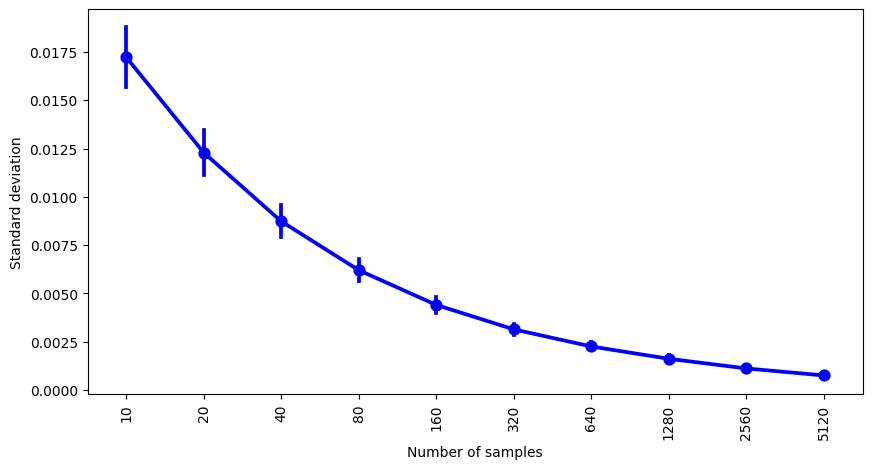

In [63]:
fig = plt.figure(figsize =(10, 5))
ax = fig.add_subplot(111)
ax = sns.pointplot(pd.DataFrame(datas),ax=ax, color="blue")
ticks = plt.xticks(rotation=90)

ax.set_ylabel("Standard deviation")
ax.set_xlabel("Number of samples")
plt.savefig("figures_meeting/convergence_ecoli_noabund.png",bbox_inches="tight")

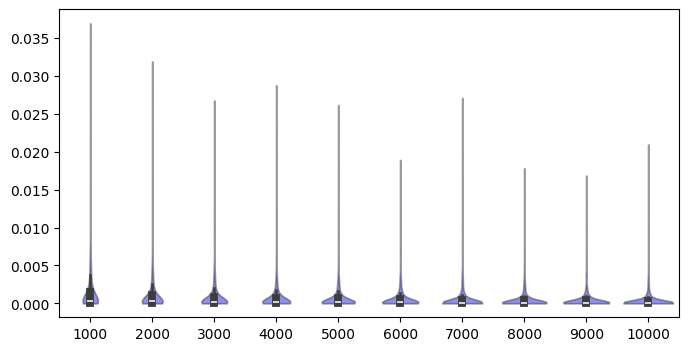

In [64]:
fig = plt.figure(figsize =(8, 4))
ax = fig.add_subplot(111)
ax = sns.violinplot(pd.DataFrame(datas_higher_res),cut=0,ax=ax,color="blue",alpha=0.5)
#ax.set_ylim([0,1e-2])

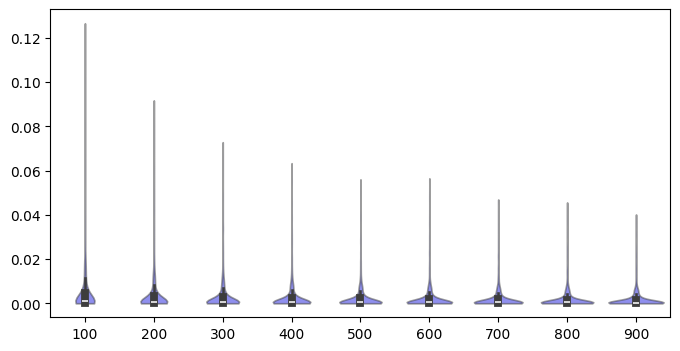

In [65]:
fig = plt.figure(figsize =(8, 4))
ax = fig.add_subplot(111)
ax = sns.violinplot(pd.DataFrame(datas_lower_res),cut=0,ax=ax,color="blue",alpha=0.5)
#ax.set_ylim([0,1e-2])

### Plotting standard deviation based on average flux rate and sample size

The x-axis represent the range of average flux rate across different sets (example: flux is between 1e-6 and 3e-6). The y-axis represents the coefficient of variance. 

We see that when the average flux is higher the coefficient of variance is lower.

In [66]:
statistics,statistics_cv = std_sampling_grouped(dfs_tot_abs,sample_sizes)

statistics_higher_res,statistics_higher_res_cv = std_sampling_grouped(dfs_tot_abs,sample_sizes_higher_res)
       

(0.0, 0.2)

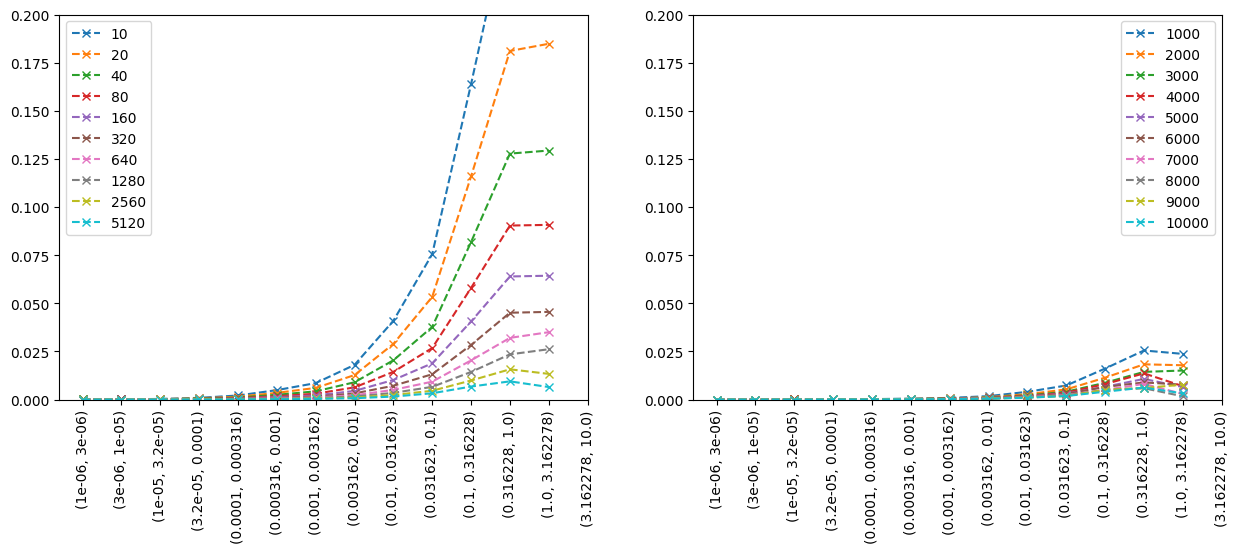

In [67]:
fig,(ax1,ax2) = plt.subplots(1,2,figsize=(15,5))

ax1 = pd.DataFrame(statistics).plot(ax=ax1,marker="x",linestyle="--")
ax1.set_xticks(np.arange(0,len(pd.DataFrame(statistics).index.values)))
ax1.set_xticklabels(pd.DataFrame(statistics).index.values,rotation=90)
ax1.legend(loc="upper left")
ax1.set_ylim([0,0.2])

ax2 = pd.DataFrame(statistics_higher_res).plot(ax=ax2,marker="x",linestyle="--")
ax2.set_xticks(np.arange(0,len(pd.DataFrame(statistics_higher_res).index.values)))
ax2.set_xticklabels(pd.DataFrame(statistics_higher_res).index.values,rotation=90)
ax2.legend(loc="upper right")
ax2.set_ylim([0,0.2])

(0.0, 100.0)

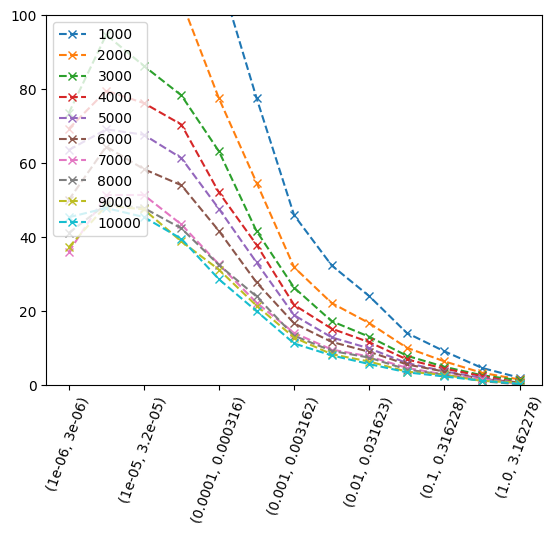

In [68]:
ax = pd.DataFrame(statistics_higher_res_cv).plot(marker="x",linestyle="--")
xticks = plt.xticks(rotation=70)
plt.legend(loc="upper left")
ax.set_ylim([0,100])

In [69]:
stats_high_res = pd.DataFrame(statistics_higher_res_cv)
diff = (stats_high_res.T.iloc[1:].reset_index(drop=True)-stats_high_res.T.iloc[:-1].reset_index(drop=True))

index = pd.Index(list(zip(np.arange(1000,10000,1000),np.arange(2000,11000,1000))))
diff.set_index(keys=index,inplace=True)

In [70]:
diff.T.mean()

1000  2000    -21.197704
2000  3000    -11.345184
3000  4000     -4.820155
4000  5000     -4.008636
5000  6000     -3.940542
6000  7000     -5.185887
7000  8000     -0.227698
8000  9000     -1.107495
9000  10000    -0.114495
dtype: float64

**Sort based on frequency**

In [71]:
statistics_freq,statistics_freq_cv = std_sampling_grouped_freq(dfs_tot_abs,sample_sizes)
statistics_freq_higher_res, statistics_freq_higher_res_cv = std_sampling_grouped_freq(dfs_tot_abs,sample_sizes_higher_res)

(0.0, 0.05)

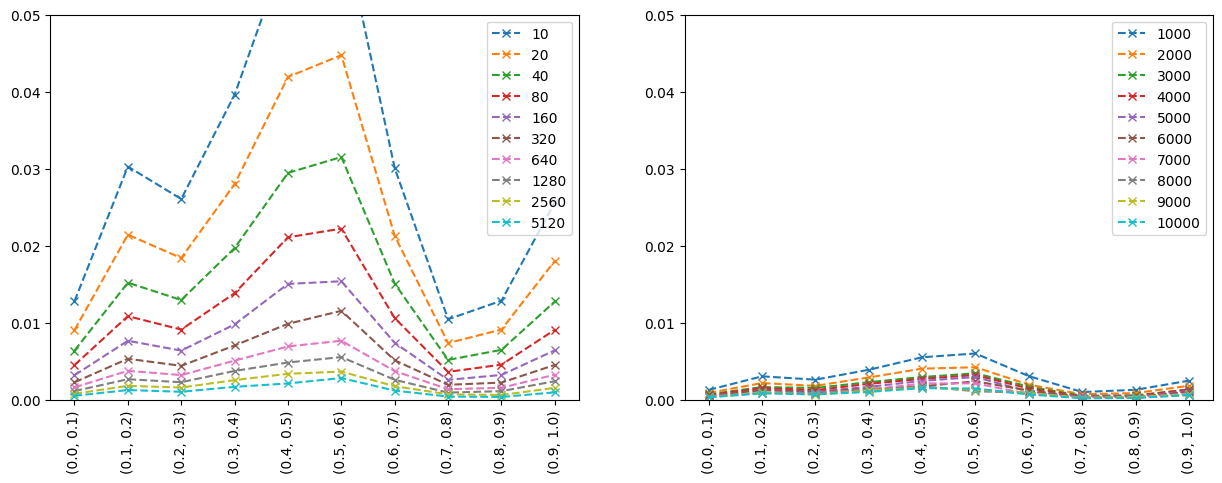

In [72]:
fig,(ax1,ax2) = plt.subplots(1,2,figsize=(15,5))
stats_df_freq = pd.DataFrame(statistics_freq)
ax1 = stats_df_freq.plot(ax=ax1,marker="x",linestyle="--")
labels =ax1.set_xticks(np.arange(len(stats_df_freq.index)))
labels = ax1.set_xticklabels(stats_df_freq.index,rotation=90)
ax1.set_ylim([0,0.05])

stats_df_freq = pd.DataFrame(statistics_freq_higher_res)
ax2 = stats_df_freq.plot(ax=ax2,marker="x",linestyle="--")
labels =ax2.set_xticks(np.arange(len(stats_df_freq.index)))
labels = ax2.set_xticklabels(stats_df_freq.index,rotation=90)
ax2.set_ylim([0,0.05])


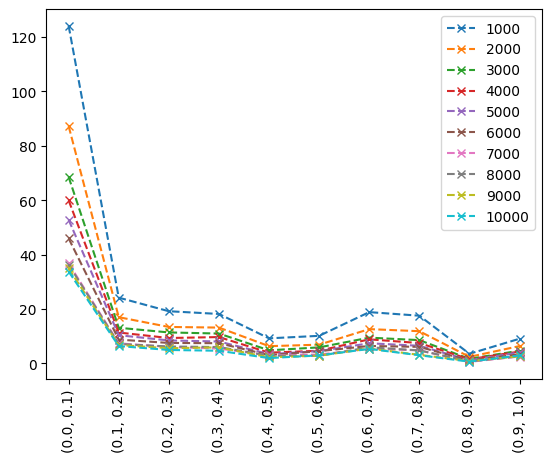

In [73]:
stats_df_freq = pd.DataFrame(statistics_freq_higher_res_cv)
ax = stats_df_freq.plot(marker="x",linestyle="--")
labels =ax.set_xticks(np.arange(len(stats_df_freq.index)))
labels = ax.set_xticklabels(stats_df_freq.index,rotation=90)

**Overview over results with filtering**

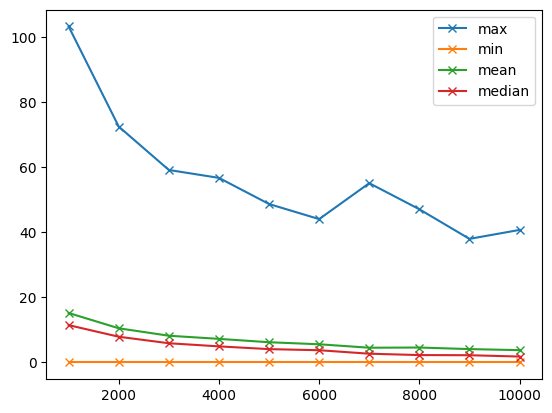

In [74]:
# For sample sizes of x calculate the frequency of the observation of values above 1e-6
sample_size=20000
data_freq = (dfs_tot_abs.T>1e-6).sum()/sample_size
index1 = data_freq>0.1

index2 = dfs_tot_abs.T.mean()>0.001
index = index1*index2

data_high_all_df = pd.DataFrame(datas_higher_res_cv)
ax = data_high_all_df.loc[index].max().plot(marker='x',label="max")
ax = data_high_all_df.loc[index].min().plot(ax=ax,marker='x',label="min")
ax = data_high_all_df.loc[index].mean().plot(ax=ax,marker='x',label="mean")
ax = data_high_all_df.loc[index].median().plot(ax=ax,marker='x',label="median")
ax.legend()


In [75]:
pd.DataFrame(datas_higher_res_cv).loc[index].mean()

1000     15.192034
2000     10.495607
3000      8.211386
4000      7.249011
5000      6.214879
6000      5.587604
7000      4.530777
8000      4.587789
9000      4.109861
10000     3.785547
dtype: float64

In [76]:
data_high_df = pd.DataFrame(datas_higher_res_cv).loc[index][3000]

max_v = data_high_df.max()
data_high_df[data_high_df>0.5*max_v]

                         type
mutant_bioH  M_3cmp_e    neg     40.327779
             M_dtmp_e    neg     37.937443
             M_no_e      neg     47.096975
mutant_icd   M_3gmp_e    neg     36.248505
             M_ala__D_e  pos     34.094312
             M_dtmp_e    neg     59.092587
             M_no_e      neg     44.405607
mutant_panZ  M_cu_e      neg     36.077869
             M_dtmp_e    neg     52.448776
             M_no_e      neg     42.931442
Name: 3000, dtype: float64

In [77]:
index_high = data_high_df[data_high_df>0.5*max_v].index
dfs_tot_abs.loc[index_high].T.mean()

                         type
mutant_bioH  M_3cmp_e    neg     0.002519
             M_dtmp_e    neg     0.001359
             M_no_e      neg     0.001349
mutant_icd   M_3gmp_e    neg     0.002519
             M_ala__D_e  pos     0.003858
             M_dtmp_e    neg     0.001778
             M_no_e      neg     0.001434
mutant_panZ  M_cu_e      neg     0.008136
             M_dtmp_e    neg     0.001708
             M_no_e      neg     0.001505
dtype: float64